# SheCraft Document Extraction Experiments

Validate the jewelry PDF corpus and inspect native text extraction before chunking.

## 1. Setup

In [1]:
import importlib
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "SheCraft" / "ai-service"]
PROJECT_ROOT = next(
    (
        candidate
        for candidate in candidates
        if (candidate / "src" / "rag" / "doc_rag").is_dir()
        and (candidate / "rag_documents").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "Could not locate ai-service. Start Jupyter from the Jewelry or ai-service folder."
    )

SRC_DIR = PROJECT_ROOT / "src" / "rag"
DOCUMENTS_DIR = PROJECT_ROOT / "rag_documents"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

PDF_FILES = sorted(DOCUMENTS_DIR.rglob("*.pdf"))
if not PDF_FILES:
    raise FileNotFoundError(f"No PDFs found in {DOCUMENTS_DIR}")

print("Project root:", PROJECT_ROOT)
print("Documents directory:", DOCUMENTS_DIR)
print("PDF count:", len(PDF_FILES))
for pdf_file in PDF_FILES:
    print(" -", pdf_file.relative_to(DOCUMENTS_DIR))

Project root: C:\Users\User\Desktop\LLMs - Samer Saab\Project\Jewelry\SheCraft\ai-service
Documents directory: C:\Users\User\Desktop\LLMs - Samer Saab\Project\Jewelry\SheCraft\ai-service\rag_documents
PDF count: 40
 - birthstone_guide.pdf
 - engagement_ring_settings_guide.pdf
 - gems_pdfs\alexandrite.pdf
 - gems_pdfs\amber.pdf
 - gems_pdfs\amethyst.pdf
 - gems_pdfs\ametrine.pdf
 - gems_pdfs\aquamarine.pdf
 - gems_pdfs\citrine.pdf
 - gems_pdfs\diamond.pdf
 - gems_pdfs\emerald.pdf
 - gems_pdfs\fancy_color_diamond.pdf
 - gems_pdfs\garnet.pdf
 - gems_pdfs\iolite.pdf
 - gems_pdfs\jade.pdf
 - gems_pdfs\kunzite.pdf
 - gems_pdfs\lapis_lazuli.pdf
 - gems_pdfs\moonstone.pdf
 - gems_pdfs\morganite.pdf
 - gems_pdfs\opal.pdf
 - gems_pdfs\pearl.pdf
 - gems_pdfs\peridot.pdf
 - gems_pdfs\rose_quartz.pdf
 - gems_pdfs\ruby.pdf
 - gems_pdfs\sapphire.pdf
 - gems_pdfs\spinel.pdf
 - gems_pdfs\sunstone.pdf
 - gems_pdfs\tanzanite.pdf
 - gems_pdfs\topaz.pdf
 - gems_pdfs\tourmaline.pdf
 - gems_pdfs\turquoise.pd

## 2. Load and Inspect the Jewelry Corpus

### 2.1 Validate the Document and Detect Its Type

In [2]:
loader_module = importlib.import_module(
    "doc_rag.1_loader"
)

load_document = loader_module.load_document
document_infos = []
validation_failures = []

for pdf_file in PDF_FILES:
    try:
        document_infos.append(load_document(pdf_file))
    except Exception as error:
        validation_failures.append({
            "file_name": pdf_file.name,
            "error": str(error),
        })

document_inventory = pd.DataFrame(document_infos) if "pd" in globals() else None
print(f"Validated: {len(document_infos)}/{len(PDF_FILES)} PDFs")
if validation_failures:
    print("Validation failures:")
    for failure in validation_failures:
        print(" -", failure)
else:
    print("Validation failures: 0")

Validated: 40/40 PDFs
Validation failures: 0


### 2.2 Extract Native PDF Content

In [3]:
extraction_module = importlib.import_module(
    "doc_rag.2_extraction"
)

extract_pdf = extraction_module.extract_pdf
extracted_documents = []
extraction_failures = []

# Prefer native extraction and use Tesseract only when a page has no usable
# text layer. A failure in one PDF does not stop the remaining documents.
for index, pdf_file in enumerate(PDF_FILES, start=1):
    print(f"[{index:02d}/{len(PDF_FILES)}] {pdf_file.name}")
    try:
        extracted_documents.append(
            extract_pdf(
                pdf_file,
                compare_ocr=False,
                use_ocr_fallback=True,
            )
        )
    except Exception as error:
        extraction_failures.append({
            "file_name": pdf_file.name,
            "error": str(error),
        })
        print("  FAILED:", error)

print(f"\nExtracted: {len(extracted_documents)}/{len(PDF_FILES)} PDFs")
print("Extraction failures:", len(extraction_failures))

[01/40] birthstone_guide.pdf
[02/40] engagement_ring_settings_guide.pdf
[03/40] alexandrite.pdf
[04/40] amber.pdf
[05/40] amethyst.pdf
[06/40] ametrine.pdf
[07/40] aquamarine.pdf
[08/40] citrine.pdf
[09/40] diamond.pdf
[10/40] emerald.pdf
[11/40] fancy_color_diamond.pdf
[12/40] garnet.pdf
[13/40] iolite.pdf
[14/40] jade.pdf
[15/40] kunzite.pdf
[16/40] lapis_lazuli.pdf
[17/40] moonstone.pdf
[18/40] morganite.pdf
[19/40] opal.pdf
[20/40] pearl.pdf
[21/40] peridot.pdf
[22/40] rose_quartz.pdf
[23/40] ruby.pdf
[24/40] sapphire.pdf
[25/40] spinel.pdf
[26/40] sunstone.pdf
[27/40] tanzanite.pdf
[28/40] topaz.pdf
[29/40] tourmaline.pdf
[30/40] turquoise.pdf
[31/40] zircon.pdf
[32/40] gemstone_diamond_pearl_buying_guide.pdf
[33/40] gold_colors_guide.pdf
[34/40] jewelry_chain_guide.pdf
[35/40] jewelry_settings_bench_guide.pdf
[36/40] necklace_stacking_guide.pdf
[37/40] pearl_care_cleaning_guide.pdf
[38/40] ring_metals_everyday_wear.pdf
[39/40] ring_size_guide.pdf
[40/40] ring_sizing_technical_gui

## 3. Build the Page Inventory

In [4]:
import pandas as pd

if not extracted_documents:
    raise RuntimeError("No documents were extracted successfully.")

page_inventory = pd.DataFrame([
    {
        "file_name": document["file_name"],
        "page_number": page["page_number"],
        "native_text_length": page["text_length"],
        "final_text_length": page["final_text_length"],
        "text_blocks": len(page["text_blocks"]),
        "width": page["width"],
        "height": page["height"],
        "native_text_usable": page["native_text_usable"],
        "extraction_method": page["extraction_method"],
        "is_empty": not bool(page["final_text"].strip()),
        "needs_ocr_review": page["extraction_method"] == "no_text",
        "mojibake_repaired": page.get("had_mojibake", False),
        "html_artifact_lines_removed": page.get("html_artifact_line_count", 0),
    }
    for document in extracted_documents
    for page in document["pages"]
])

print("Inventory pages:", len(page_inventory))
display(page_inventory.head(10))

Inventory pages: 185


,file_name,page_number,native_text_length,final_text_length,text_blocks,width,height,native_text_usable,extraction_method,is_empty,needs_ocr_review,mojibake_repaired,html_artifact_lines_removed
0,birthstone_guide.pdf,1,67,66,2,612.0,792.0,True,native,False,False,False,0
1,engagement_ring_settings_guide.pdf,1,1029,554,5,612.0,792.0,True,native,False,False,False,0
2,engagement_ring_settings_guide.pdf,2,2460,1303,10,612.0,792.0,True,native,False,False,False,0
3,engagement_ring_settings_guide.pdf,3,2103,1136,6,612.0,792.0,True,native,False,False,False,0
4,engagement_ring_settings_guide.pdf,4,2810,1517,6,612.0,792.0,True,native,False,False,False,0
5,engagement_ring_settings_guide.pdf,5,2819,1527,7,612.0,792.0,True,native,False,False,False,0
6,engagement_ring_settings_guide.pdf,6,2893,1562,8,612.0,792.0,True,native,False,False,False,0
7,engagement_ring_settings_guide.pdf,7,2343,1260,8,612.0,792.0,True,native,False,False,False,0
8,engagement_ring_settings_guide.pdf,8,2435,1311,9,612.0,792.0,True,native,False,False,False,0
9,engagement_ring_settings_guide.pdf,9,2938,1589,8,612.0,792.0,True,native,False,False,False,0


## 4. Compare Extraction Coverage

In [5]:
corpus_summary = page_inventory.groupby("file_name").agg(
    pages=("page_number", "count"),
    extracted_characters=("final_text_length", "sum"),
    empty_pages=("is_empty", "sum"),
    pages_needing_ocr_review=("needs_ocr_review", "sum"),
    ocr_pages=(
        "extraction_method",
        lambda methods: methods.isin(["ocr", "ocr_supplement"]).sum(),
    ),
    pages_with_repaired_encoding=("mojibake_repaired", "sum"),
    html_artifact_lines_removed=("html_artifact_lines_removed", "sum"),
    minimum_page_characters=("final_text_length", "min"),
    median_page_characters=("final_text_length", "median"),
    maximum_page_characters=("final_text_length", "max"),
    text_blocks=("text_blocks", "sum"),
).sort_values(
    ["pages_needing_ocr_review", "extracted_characters"],
    ascending=[False, True],
)

display(corpus_summary)
if extraction_failures:
    display(pd.DataFrame(extraction_failures))

,pages,extracted_characters,empty_pages,pages_needing_ocr_review,ocr_pages,pages_with_repaired_encoding,html_artifact_lines_removed,minimum_page_characters,median_page_characters,maximum_page_characters,text_blocks
file_name,,,,,,,,,,,
ring_sizing_technical_guide.pdf,21,3484,5,5,1,0,0,0,143.0,700,55
moonstone.pdf,3,2425,1,1,0,0,0,0,1066.0,1359,102
amethyst.pdf,3,2604,1,1,0,0,8,0,1068.0,1536,104
engagement_ring_settings_guide.pdf,15,19066,1,1,0,0,0,0,1338.0,1741,106
birthstone_guide.pdf,1,66,0,0,0,0,0,66,66.0,66,2
pearl_care_cleaning_guide.pdf,3,1872,0,0,0,0,0,124,684.0,1064,27
morganite.pdf,3,2179,0,0,0,0,0,466,475.0,1238,97
ametrine.pdf,2,2207,0,0,0,0,8,745,1103.5,1462,85
lapis_lazuli.pdf,3,2258,0,0,0,0,0,462,559.0,1237,97


## 5. Select Representative Pages

In [6]:
representative_pages = pd.concat([
    group.nsmallest(1, "final_text_length").assign(selection="least text")
    for _, group in page_inventory.groupby("file_name", sort=False)
] + [
    group.nlargest(1, "final_text_length").assign(selection="most text")
    for _, group in page_inventory.groupby("file_name", sort=False)
], ignore_index=True).sort_values(["file_name", "selection"])

display(
    representative_pages[[
        "file_name",
        "selection",
        "page_number",
        "final_text_length",
        "text_blocks",
        "extraction_method",
        "is_empty",
    ]]
)

,file_name,selection,page_number,final_text_length,text_blocks,extraction_method,is_empty
2,alexandrite.pdf,least text,3,412,20,native_layout_aware,False
42,alexandrite.pdf,most text,1,1291,50,native_layout_aware,False
3,amber.pdf,least text,2,973,39,native_layout_aware,False
43,amber.pdf,most text,1,1551,57,native_layout_aware,False
4,amethyst.pdf,least text,3,0,0,no_text,True
...,...,...,...,...,...,...,...
68,tourmaline.pdf,most text,1,1243,52,native,False
29,turquoise.pdf,least text,3,334,19,native_layout_aware,False
69,turquoise.pdf,most text,1,1259,51,native_layout_aware,False
30,zircon.pdf,least text,3,443,23,native_layout_aware,False


## 6. Inspect Native Text and Reading Order

In [7]:
MAX_EXCERPT_CHARACTERS = 800

for extracted_document in extracted_documents:
    document_pages = page_inventory[
        page_inventory["file_name"] == extracted_document["file_name"]
    ]
    text_heavy_page_number = int(
        document_pages.nlargest(1, "final_text_length").iloc[0]["page_number"]
    )
    page = extracted_document["pages"][text_heavy_page_number - 1]
    excerpt = page["final_text"][:MAX_EXCERPT_CHARACTERS].strip()

    print("\n" + "=" * 80)
    print("DOCUMENT:", extracted_document["file_name"])
    print("PAGE:", text_heavy_page_number)
    print("METHOD:", page["extraction_method"])
    print("CHARACTERS:", page["final_text_length"])
    print("EXCERPT:")
    print(excerpt or "[NO EXTRACTED TEXT]")


DOCUMENT: birthstone_guide.pdf
PAGE: 1
METHOD: native
CHARACTERS: 66
EXCERPT:
FROM THE VAULT
GIA Celebrates Birthstones
April 2017 – August 2017

DOCUMENT: engagement_ring_settings_guide.pdf
PAGE: 11
METHOD: native
CHARACTERS: 1741
EXCERPT:
The pavé setting features small gemstones set closely together to create a
continuous surface of sparkle. The stones are typically secured with tiny beads
or prongs of metal, allowing the band or halo to appear covered with diamonds
or other gemstones.
Pavé settings are commonly used along the band or in halo designs around a
center stone, where they add extra brilliance and a delicate, decorative effect.
Rings with pavé settings may require occasional maintenance to ensure the
stones remain secure. Pavé-set bands can also be more difficult to resize, since
adjusting the ring may disturb the small stones.
Cathedral Setting Style
The cathedral setting style features arches of metal that rise from the shank to
support the center setting. These upward

### 6.1 Inspect Pages with Little or No Extracted Text

These are the only pages we should consider for OCR or document repair.

In [8]:
lowest_text_pages = page_inventory.sort_values(
    ["final_text_length", "file_name", "page_number"]
).head(20)

display(lowest_text_pages)

documents_by_name = {
    document["file_name"]: document
    for document in extracted_documents
}

for row in lowest_text_pages.itertuples(index=False):
    page = documents_by_name[row.file_name]["pages"][row.page_number - 1]
    excerpt = page["final_text"][:500].strip() or "[NO EXTRACTED TEXT]"
    print("\n" + "=" * 80)
    print(f"{row.file_name} - page {row.page_number}")
    print(f"method={row.extraction_method}, characters={row.final_text_length}")
    print(excerpt)

,file_name,page_number,native_text_length,final_text_length,text_blocks,width,height,native_text_usable,extraction_method,is_empty,needs_ocr_review,mojibake_repaired,html_artifact_lines_removed
23,amethyst.pdf,3,0,0,0,595.919983,842.880005,False,no_text,True,True,False,0
15,engagement_ring_settings_guide.pdf,15,0,0,0,612.000000,792.000000,False,no_text,True,True,False,0
54,moonstone.pdf,3,0,0,0,595.919983,842.880005,False,no_text,True,True,False,0
167,ring_sizing_technical_guide.pdf,4,0,0,0,612.000000,792.000000,False,no_text,True,True,False,0
173,ring_sizing_technical_guide.pdf,10,0,0,0,612.000000,792.000000,False,no_text,True,True,False,0
178,ring_sizing_technical_guide.pdf,15,0,0,0,612.000000,792.000000,False,no_text,True,True,False,0
180,ring_sizing_technical_guide.pdf,17,0,0,0,612.000000,792.000000,False,no_text,True,True,False,0
182,ring_sizing_technical_guide.pdf,19,0,0,0,612.000000,792.000000,False,no_text,True,True,False,0
176,ring_sizing_technical_guide.pdf,13,11,11,1,612.000000,792.000000,True,native,False,False,False,0
0,birthstone_guide.pdf,1,67,66,2,612.000000,792.000000,True,native,False,False,False,0



amethyst.pdf - page 3
method=no_text, characters=0
[NO EXTRACTED TEXT]

engagement_ring_settings_guide.pdf - page 15
method=no_text, characters=0
[NO EXTRACTED TEXT]

moonstone.pdf - page 3
method=no_text, characters=0
[NO EXTRACTED TEXT]

ring_sizing_technical_guide.pdf - page 4
method=no_text, characters=0
[NO EXTRACTED TEXT]

ring_sizing_technical_guide.pdf - page 10
method=no_text, characters=0
[NO EXTRACTED TEXT]

ring_sizing_technical_guide.pdf - page 15
method=no_text, characters=0
[NO EXTRACTED TEXT]

ring_sizing_technical_guide.pdf - page 17
method=no_text, characters=0
[NO EXTRACTED TEXT]

ring_sizing_technical_guide.pdf - page 19
method=no_text, characters=0
[NO EXTRACTED TEXT]

ring_sizing_technical_guide.pdf - page 13
method=native, characters=11
Bridal Sets

birthstone_guide.pdf - page 1
method=native, characters=66
FROM THE VAULT
GIA Celebrates Birthstones
April 2017 – August 2017

ring_sizing_technical_guide.pdf - page 7
method=native, characters=93
BEST PRACTICES FOR 

### 6.2 Visually Review Pages Still Missing Text

Render only pages that remain empty after native extraction and OCR. This distinguishes intentionally blank pages from extraction failures.


engagement_ring_settings_guide.pdf - page 15


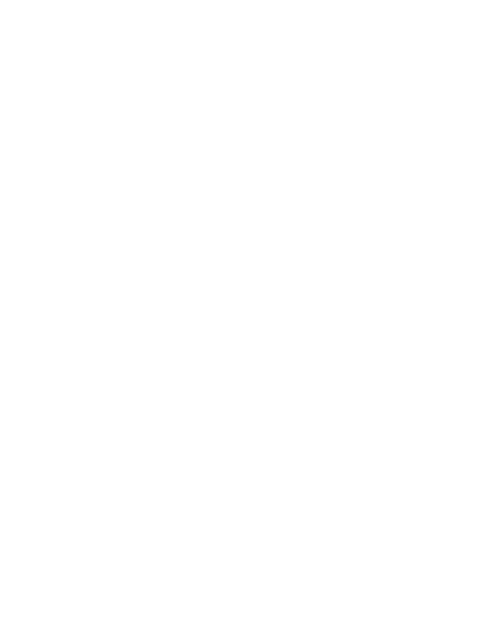


amethyst.pdf - page 3


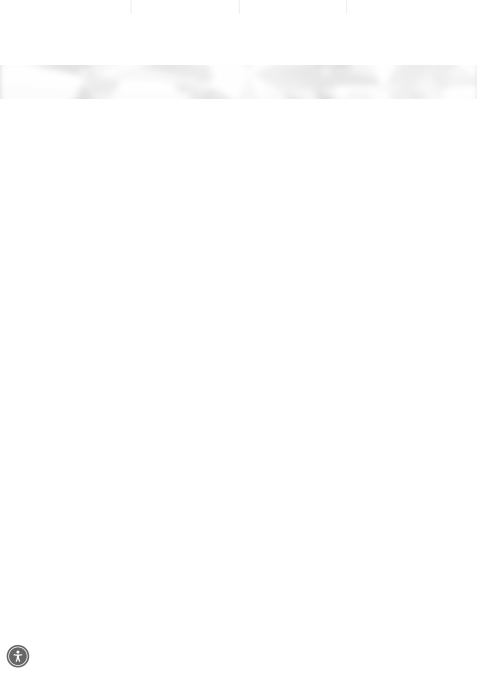


moonstone.pdf - page 3


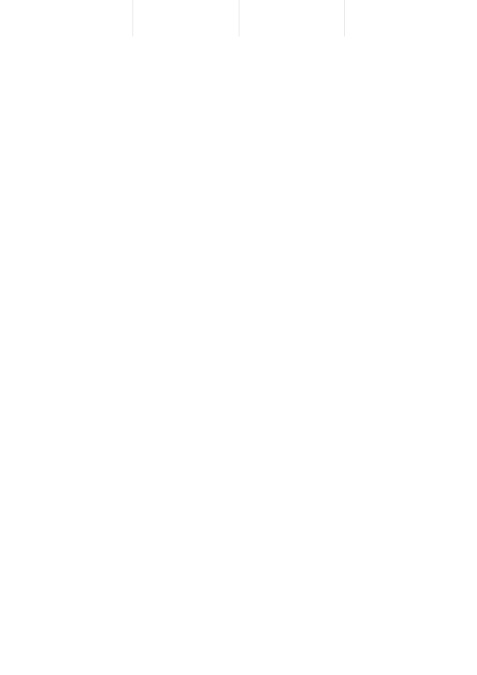


ring_sizing_technical_guide.pdf - page 4


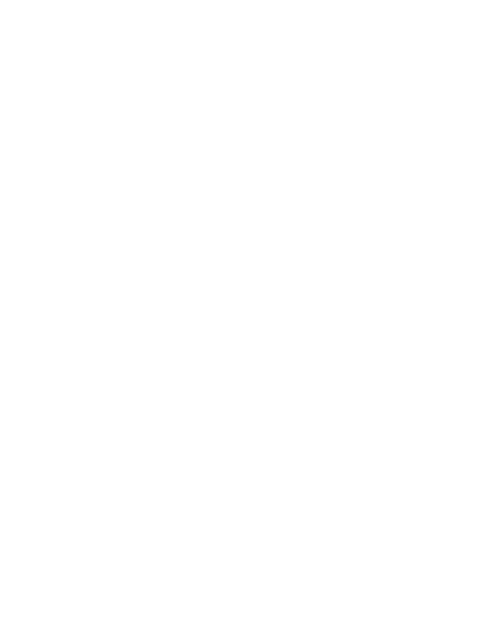


ring_sizing_technical_guide.pdf - page 10


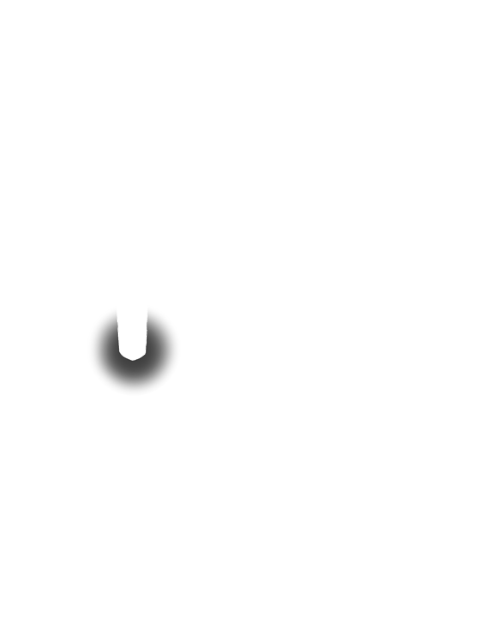


ring_sizing_technical_guide.pdf - page 15


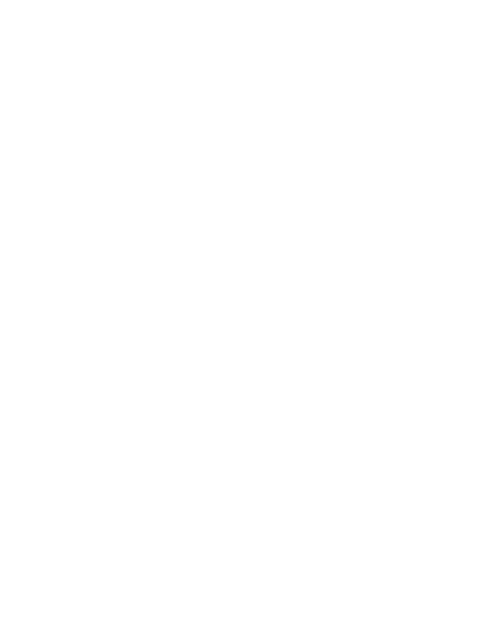


ring_sizing_technical_guide.pdf - page 17


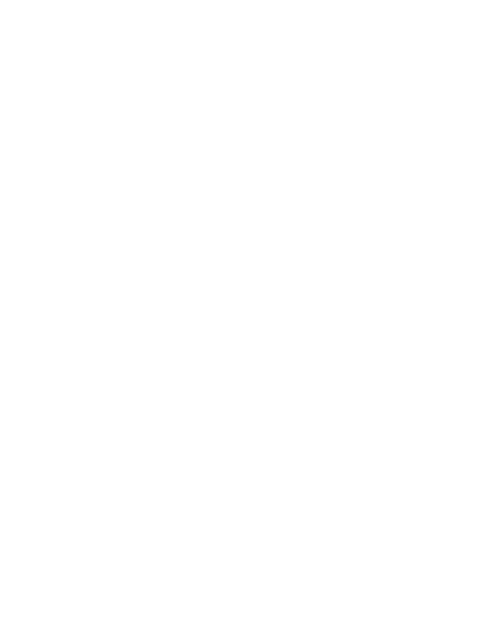


ring_sizing_technical_guide.pdf - page 19


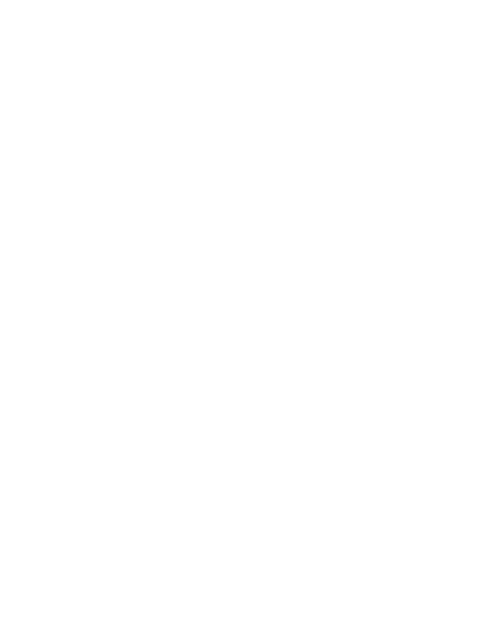

In [9]:
import pymupdf
from IPython.display import Image as NotebookImage

pages_for_visual_review = page_inventory[
    page_inventory["needs_ocr_review"]
].head(12)

if pages_for_visual_review.empty:
    print("No pages require visual review.")
else:
    for row in pages_for_visual_review.itertuples(index=False):
        document = documents_by_name[row.file_name]
        with pymupdf.open(document["source_path"]) as pdf:
            page = pdf.load_page(row.page_number - 1)
            pixmap = page.get_pixmap(
                matrix=pymupdf.Matrix(0.8, 0.8),
                alpha=False,
            )

        print("\n" + "=" * 80)
        print(f"{row.file_name} - page {row.page_number}")
        display(NotebookImage(data=pixmap.tobytes("png"), width=500))

## 7. Inspect Automatic Boilerplate Detection

Review repeated headers, footers, and navigation text detected across each document before chunking.

In [10]:
MAX_BOILERPLATE_LINES_PER_DOCUMENT = 10

boilerplate_summary = []
for extracted_document in extracted_documents:
    boilerplate = extracted_document["boilerplate_lines"]
    boilerplate_summary.append({
        "file_name": extracted_document["file_name"],
        "detected_boilerplate_lines": len(boilerplate),
    })

    if not boilerplate:
        continue

    print("\n" + "=" * 80)
    print("DOCUMENT:", extracted_document["file_name"])
    print("DETECTED BOILERPLATE:", len(boilerplate))
    for line in boilerplate[:MAX_BOILERPLATE_LINES_PER_DOCUMENT]:
        print(" -", repr(line))
    if len(boilerplate) > MAX_BOILERPLATE_LINES_PER_DOCUMENT:
        print(" ... output capped; review the document object for all lines")

display(
    pd.DataFrame(boilerplate_summary)
    .sort_values("detected_boilerplate_lines", ascending=False)
    .reset_index(drop=True)
)

,file_name,detected_boilerplate_lines
0,birthstone_guide.pdf,0
1,engagement_ring_settings_guide.pdf,0
2,alexandrite.pdf,0
3,amber.pdf,0
4,amethyst.pdf,0
5,ametrine.pdf,0
6,aquamarine.pdf,0
7,citrine.pdf,0
8,diamond.pdf,0
9,emerald.pdf,0
